# RTP - System Identification lab exercise


Readme.txt exerpt 

```
Data-setup:

Real-time measured signals with following setup:

first  column: t/s
second column: y(t)
third  column: x(t)

columns separated by: ,
decimal separator   : .
```

In [63]:
import matplotlib.pyplot as plt
import math 
import numpy as np
import csv




# Task 

system files:

sys0.csv  
sys1.csv  
sys2.csv



2.2 Experiment 2 – System identification
In this experiment, the parameters of various dynamic systems have to be determined experimentally. 
For this purpose, step responses or impulse responses (see xe(t)) were recorded and saved as text files. All parameters (numerical values and units) necessary for a complete description of the system must be determined using Matlab or Python. 
Document every step thoroughly; show the graphs of the system responses with correct axis labels and add the evaluations you have programmed (tangents, intersections, etc.) and explain your approach clearly and concisely! Display

f) Determine the system behavior experimentally using the recorded step or impulse responses of
the given systems and their parameters (values and units!). Document the results, show the
essential commands and specify the differential equation and transfer function describing the
system.
g) Provide a real example for each of the determined system behaviors with a description of the
respective input and output variables!
h) Compare the given system responses with the responses of your identified system in the same
graphs and also show the deviation for each system!

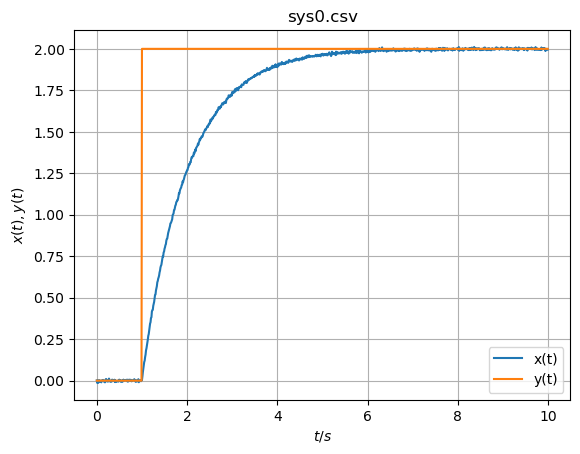

In [64]:
# Plot for sys0.csv
data0 = np.loadtxt('data/sys0.csv', delimiter=',', skiprows=1)
plt.plot(data0[:, 0], data0[:, 2], label='x(t)')
plt.plot(data0[:, 0], data0[:, 1], label='y(t)')
plt.title('sys0.csv')
plt.xlabel('$t/s$')
plt.ylabel('$x(t), y(t)$')
plt.grid()
plt.legend()
plt.show()

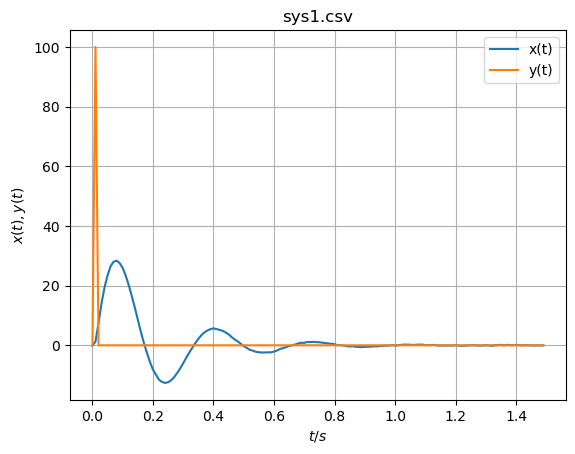

In [65]:
# Plot for sys1.csv
data1 = np.loadtxt('data/sys1.csv', delimiter=',', skiprows=1)
plt.plot(data1[:, 0], data1[:, 2], label='x(t)')
plt.plot(data1[:, 0], data1[:, 1], label='y(t)')
plt.title('sys1.csv')
plt.xlabel('$t/s$')
plt.ylabel('$x(t), y(t)$')
plt.grid()
plt.legend()
plt.show()

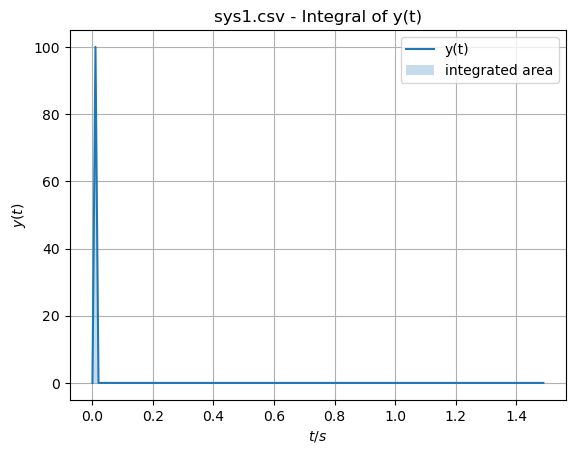

Integrated window: 0.00 s to 0.02 s
Integral of y(t): 1.000000


In [81]:
# Integral of sys1 y(t) over the pulse window
t_vals = data1[:, 0]
y_vals = data1[:, 1]

# Find the non-zero pulse and include the zero samples on both sides,
# so the triangle-shaped pulse is integrated over its full 0.02 s window.
pulse_mask = y_vals != 0

if np.any(pulse_mask):
    pulse_indices = np.flatnonzero(pulse_mask)
    start_idx = max(pulse_indices[0] - 1, 0)
    end_idx = min(pulse_indices[-1] + 1, len(y_vals) - 1)

    t_window = t_vals[start_idx:end_idx + 1]
    y_window = y_vals[start_idx:end_idx + 1]

    integral_y = np.trapezoid(y_window, t_window)

    plt.figure()
    plt.plot(t_vals, y_vals, label='y(t)')
    plt.fill_between(t_window, y_window, alpha=0.25, label='integrated area')
    plt.title('sys1.csv - Integral of y(t)')
    plt.xlabel('$t/s$')
    plt.ylabel('$y(t)$')
    plt.grid()
    plt.legend()
    plt.show()

    print(f'Integrated window: {t_window[0]:.2f} s to {t_window[-1]:.2f} s')
    print(f'Integral of y(t): {integral_y:.6f}')
else:
    print('No non-zero samples found in y(t).')

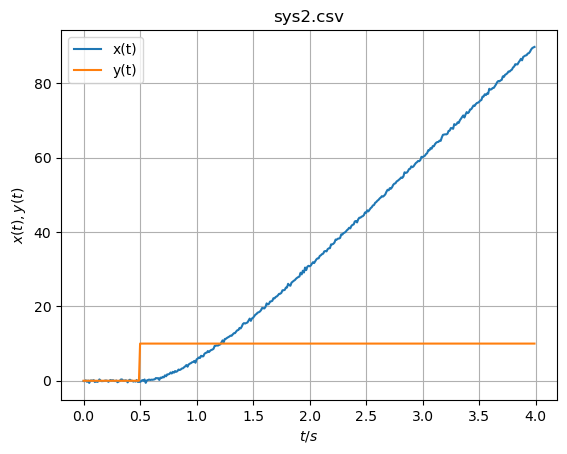

In [66]:
# Plot for sys2.csv
data2 = np.loadtxt('data/sys2.csv', delimiter=',', skiprows=1)
plt.plot(data2[:, 0], data2[:, 2], label='x(t)')
plt.plot(data2[:, 0], data2[:, 1], label='y(t)')
plt.title('sys2.csv')
plt.xlabel('$t/s$')
plt.ylabel('$x(t), y(t)$')
plt.grid()
plt.legend()
plt.show()

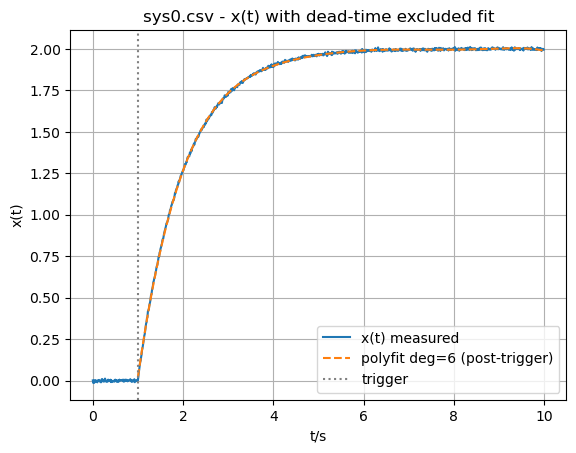

Calculated polyfit function for sys0:
            6            5           4          3         2
-6.207e-05 x + 0.002433 x - 0.03921 x + 0.3349 x - 1.618 x + 4.27 x - 2.926


In [78]:
# Polynomial fit for x(t) in sys0.csv (exclude initial dead time)
t_vals = data0[:, 0]
y_vals = data0[:, 1]
x_vals = data0[:, 2]

sys0_poly_deg = 6

# Detect trigger at y(t) step from ~0 to ~2 (crossing midpoint).
trigger_candidates = np.where((y_vals[:-1] < 1.0) & (y_vals[1:] >= 1.0))[0]
if len(trigger_candidates) > 0:
    trigger_idx = trigger_candidates[0] + 1
else:
    trigger_idx = 0

t_fit = t_vals[trigger_idx:]
x_fit_data = x_vals[trigger_idx:]
coeffs = np.polyfit(t_fit, x_fit_data, deg=sys0_poly_deg)
poly = np.poly1d(coeffs)

# Show fit only after trigger so dead time is not included visually.
x_fit = np.full_like(x_vals, np.nan, dtype=float)
x_fit[trigger_idx:] = poly(t_fit)

plt.figure()
plt.plot(t_vals, x_vals, label='x(t) measured')
plt.plot(t_vals, x_fit, '--', label=f'polyfit deg={sys0_poly_deg} (post-trigger)')
plt.axvline(t_vals[trigger_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys0.csv - x(t) with dead-time excluded fit')
plt.xlabel('t/s')
plt.ylabel('x(t)')
plt.grid()
plt.legend()
plt.show()

print('Calculated polyfit function for sys0:')
print(poly)

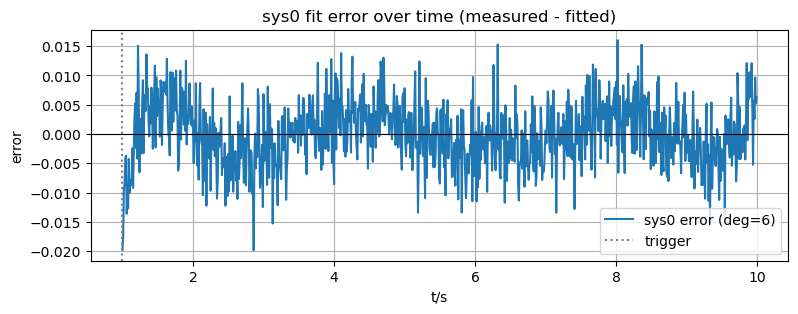

sys0 (deg=6) -> RMSE=0.005634, MAE=0.004517


In [79]:
# Fit error over time for sys0 (adapts to sys0_poly_deg)
deg0 = globals().get('sys0_poly_deg', 6)
t0 = data0[:, 0]
y0 = data0[:, 1]
x0 = data0[:, 2]

trigger0_candidates = np.where((y0[:-1] < 1.0) & (y0[1:] >= 1.0))[0]
trigger0_idx = trigger0_candidates[0] + 1 if len(trigger0_candidates) > 0 else 0

poly0 = np.poly1d(np.polyfit(t0[trigger0_idx:], x0[trigger0_idx:], deg=deg0))
x0_fit = np.full_like(x0, np.nan, dtype=float)
x0_fit[trigger0_idx:] = poly0(t0[trigger0_idx:])
err0 = x0 - x0_fit

plt.figure(figsize=(9, 3))
plt.plot(t0, err0, label=f'sys0 error (deg={deg0})')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.axvline(t0[trigger0_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys0 fit error over time (measured - fitted)')
plt.xlabel('t/s')
plt.ylabel('error')
plt.grid()
plt.legend()
plt.show()

rmse0 = np.sqrt(np.nanmean(err0**2))
mae0 = np.nanmean(np.abs(err0))
print(f'sys0 (deg={deg0}) -> RMSE={rmse0:.6f}, MAE={mae0:.6f}')

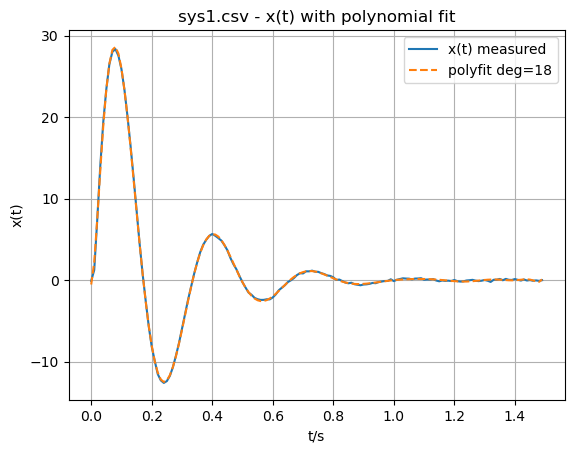

Calculated polyfit function for sys1:
           18             17             16             15
6.447e+06 x  - 8.908e+07 x  + 5.645e+08 x  - 2.173e+09 x 
              14             13             12             11
 + 5.674e+09 x  - 1.062e+10 x  + 1.471e+10 x  - 1.531e+10 x 
              10             9             8             7
 + 1.206e+10 x  - 7.198e+09 x + 3.238e+09 x - 1.091e+09 x
              6           5             4             3             2
 + 2.737e+08 x - 5.1e+07 x + 6.942e+06 x - 6.309e+05 x + 2.772e+04 x + 51.23 x - 0.5298


In [69]:
# Polynomial fit for x(t) in sys1.csv (no dead time exclusion)
t_vals = data1[:, 0]
x_vals = data1[:, 2]

sys1_poly_deg = 18

coeffs = np.polyfit(t_vals, x_vals, deg=sys1_poly_deg)
poly = np.poly1d(coeffs)
x_fit = poly(t_vals)


plt.figure()
plt.plot(t_vals, x_vals, label='x(t) measured')
plt.plot(t_vals, x_fit, '--', label=f'polyfit deg={sys1_poly_deg}')
plt.title('sys1.csv - x(t) with polynomial fit')
plt.xlabel('t/s')
plt.ylabel('x(t)')
plt.grid()
plt.legend()
plt.show()

print('Calculated polyfit function for sys1:')
print(poly)

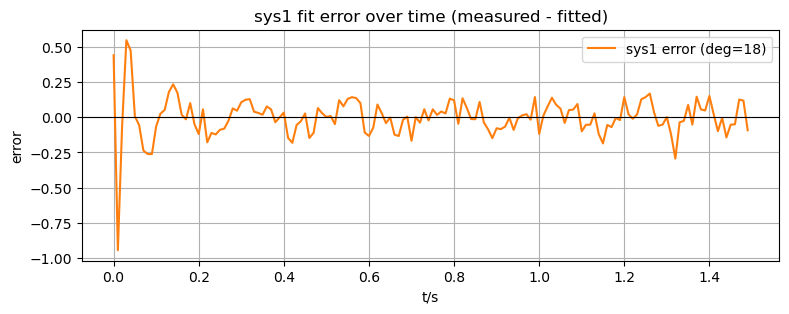

sys1 (deg=18) -> RMSE=0.141838, MAE=0.092202


In [70]:
# Fit error over time for sys1 (adapts to sys1_poly_deg)
deg1 = globals().get('sys1_poly_deg', 18)
t1 = data1[:, 0]
x1 = data1[:, 2]

poly1 = np.poly1d(np.polyfit(t1, x1, deg=deg1))
x1_fit = poly1(t1)
err1 = x1 - x1_fit

plt.figure(figsize=(9, 3))
plt.plot(t1, err1, label=f'sys1 error (deg={deg1})', color='tab:orange')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.title('sys1 fit error over time (measured - fitted)')
plt.xlabel('t/s')
plt.ylabel('error')
plt.grid()
plt.legend()
plt.show()

rmse1 = np.sqrt(np.nanmean(err1**2))
mae1 = np.nanmean(np.abs(err1))
print(f'sys1 (deg={deg1}) -> RMSE={rmse1:.6f}, MAE={mae1:.6f}')

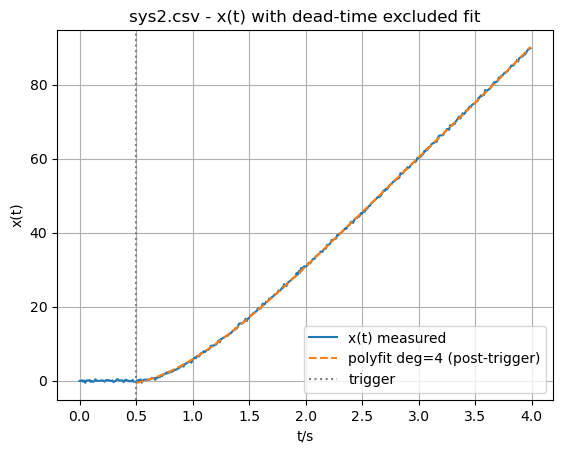

Calculated polyfit function for sys2:
        4         3         2
0.4929 x - 5.561 x + 23.29 x - 13.31 x + 0.8802


In [71]:
# Polynomial fit for x(t) in sys2.csv (exclude initial dead time)
t_vals = data2[:, 0]
y_vals = data2[:, 1]
x_vals = data2[:, 2]

sys2_poly_deg = 4

trigger_candidates = np.where((y_vals[:-1] < 1.0) & (y_vals[1:] >= 1.0))[0]
if len(trigger_candidates) > 0:
    trigger_idx = trigger_candidates[0] + 1
else:
    trigger_idx = 0

t_fit = t_vals[trigger_idx:]
x_fit_data = x_vals[trigger_idx:]
coeffs = np.polyfit(t_fit, x_fit_data, deg=sys2_poly_deg)
poly = np.poly1d(coeffs)

x_fit = np.full_like(x_vals, np.nan, dtype=float)
x_fit[trigger_idx:] = poly(t_fit)

plt.figure()
plt.plot(t_vals, x_vals, label='x(t) measured')
plt.plot(t_vals, x_fit, '--', label=f'polyfit deg={sys2_poly_deg} (post-trigger)')
plt.axvline(t_vals[trigger_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys2.csv - x(t) with dead-time excluded fit')
plt.xlabel('t/s')
plt.ylabel('x(t)')
plt.grid()
plt.legend()
plt.show()

print('Calculated polyfit function for sys2:')
print(poly)

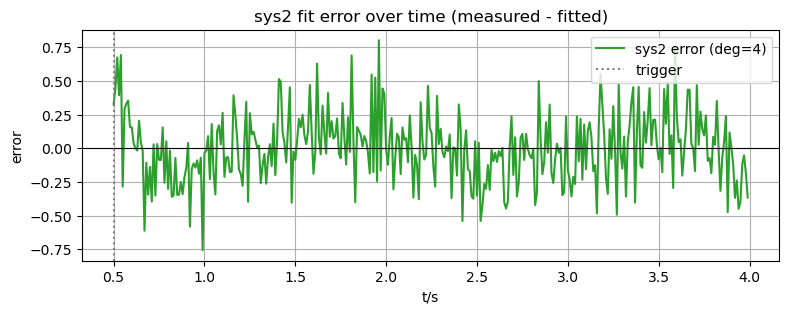

sys2 (deg=4) -> RMSE=0.255885, MAE=0.198389


In [72]:
# Fit error over time for sys2 (adapts to sys2_poly_deg)
deg2 = globals().get('sys2_poly_deg', 4)
t2 = data2[:, 0]
y2 = data2[:, 1]
x2 = data2[:, 2]

trigger2_candidates = np.where((y2[:-1] < 1.0) & (y2[1:] >= 1.0))[0]
trigger2_idx = trigger2_candidates[0] + 1 if len(trigger2_candidates) > 0 else 0

poly2 = np.poly1d(np.polyfit(t2[trigger2_idx:], x2[trigger2_idx:], deg=deg2))
x2_fit = np.full_like(x2, np.nan, dtype=float)
x2_fit[trigger2_idx:] = poly2(t2[trigger2_idx:])
err2 = x2 - x2_fit

plt.figure(figsize=(9, 3))
plt.plot(t2, err2, label=f'sys2 error (deg={deg2})', color='tab:green')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.axvline(t2[trigger2_idx], color='gray', linestyle=':', label='trigger')
plt.title('sys2 fit error over time (measured - fitted)')
plt.xlabel('t/s')
plt.ylabel('error')
plt.grid()
plt.legend()
plt.show()

rmse2 = np.sqrt(np.nanmean(err2**2))
mae2 = np.nanmean(np.abs(err2))
print(f'sys2 (deg={deg2}) -> RMSE={rmse2:.6f}, MAE={mae2:.6f}')

sys0: best RMSE at degree 19 -> 0.004786
sys0: best MAE  at degree 19 -> 0.003802
sys1: best RMSE at degree 36 -> 0.114030
sys1: best MAE  at degree 36 -> 0.078684
sys2: best RMSE at degree 19 -> 0.224799
sys2: best MAE  at degree 19 -> 0.176250


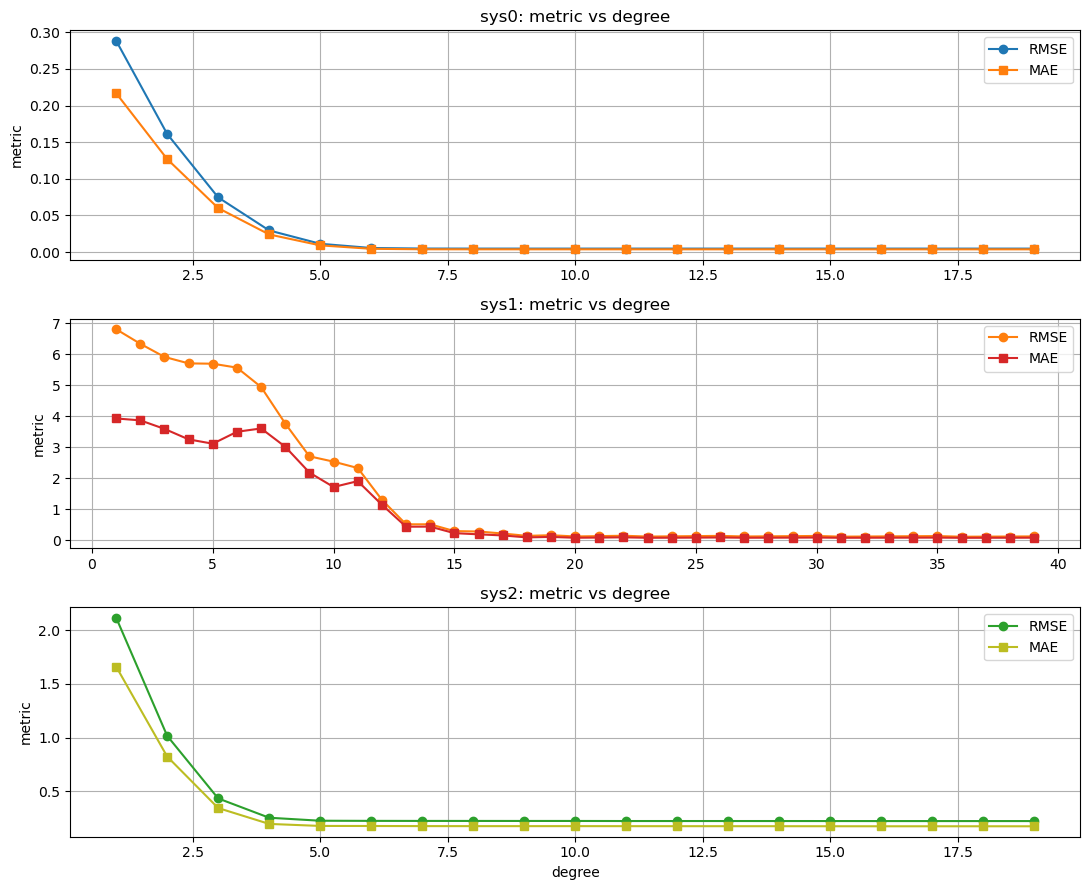

In [73]:
# Degree sweep: RMSE/MAE vs polynomial degree (objective degree selection)
import warnings

def sweep_polyfit_metrics(data, degree_range, use_deadtime, name, threshold=1.0):
    t = data[:, 0]
    y = data[:, 1]
    x = data[:, 2]

    if use_deadtime:
        trigger_candidates = np.where((y[:-1] < threshold) & (y[1:] >= threshold))[0]
        start_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
    else:
        start_idx = 0

    t_fit = t[start_idx:]
    x_fit_data = x[start_idx:]

    degrees = []
    rmses = []
    maes = []

    for deg in degree_range:
        if len(t_fit) <= deg:
            continue
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                poly = np.poly1d(np.polyfit(t_fit, x_fit_data, deg=deg))

            x_model = np.full_like(x, np.nan, dtype=float)
            x_model[start_idx:] = poly(t_fit)
            err = x - x_model

            degrees.append(deg)
            rmses.append(float(np.sqrt(np.nanmean(err**2))))
            maes.append(float(np.nanmean(np.abs(err))))
        except Exception:
            continue

    if len(degrees) == 0:
        raise ValueError(f'No valid degrees for {name}.')

    best_rmse_idx = int(np.argmin(rmses))
    best_mae_idx = int(np.argmin(maes))

    print(f'{name}: best RMSE at degree {degrees[best_rmse_idx]} -> {rmses[best_rmse_idx]:.6f}')
    print(f'{name}: best MAE  at degree {degrees[best_mae_idx]} -> {maes[best_mae_idx]:.6f}')

    return np.array(degrees), np.array(rmses), np.array(maes)

# You can change these ranges whenever you want.
deg_range0 = range(1, 20)
deg_range1 = range(1, 40)
deg_range2 = range(1, 20)

d0, r0, m0 = sweep_polyfit_metrics(data0, deg_range0, use_deadtime=True,  name='sys0')
d1, r1, m1 = sweep_polyfit_metrics(data1, deg_range1, use_deadtime=False, name='sys1')
d2, r2, m2 = sweep_polyfit_metrics(data2, deg_range2, use_deadtime=True,  name='sys2')

plt.figure(figsize=(11, 9))

plt.subplot(3, 1, 1)
plt.plot(d0, r0, '-o', label='RMSE')
plt.plot(d0, m0, '-s', label='MAE')
plt.title('sys0: metric vs degree')
plt.ylabel('metric')
plt.grid()
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(d1, r1, '-o', label='RMSE', color='tab:orange')
plt.plot(d1, m1, '-s', label='MAE', color='tab:red')
plt.title('sys1: metric vs degree')
plt.ylabel('metric')
plt.grid()
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(d2, r2, '-o', label='RMSE', color='tab:green')
plt.plot(d2, m2, '-s', label='MAE', color='tab:olive')
plt.title('sys2: metric vs degree')
plt.xlabel('degree')
plt.ylabel('metric')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

#### Section to calculate all parameters of the systems and to plot them for each system

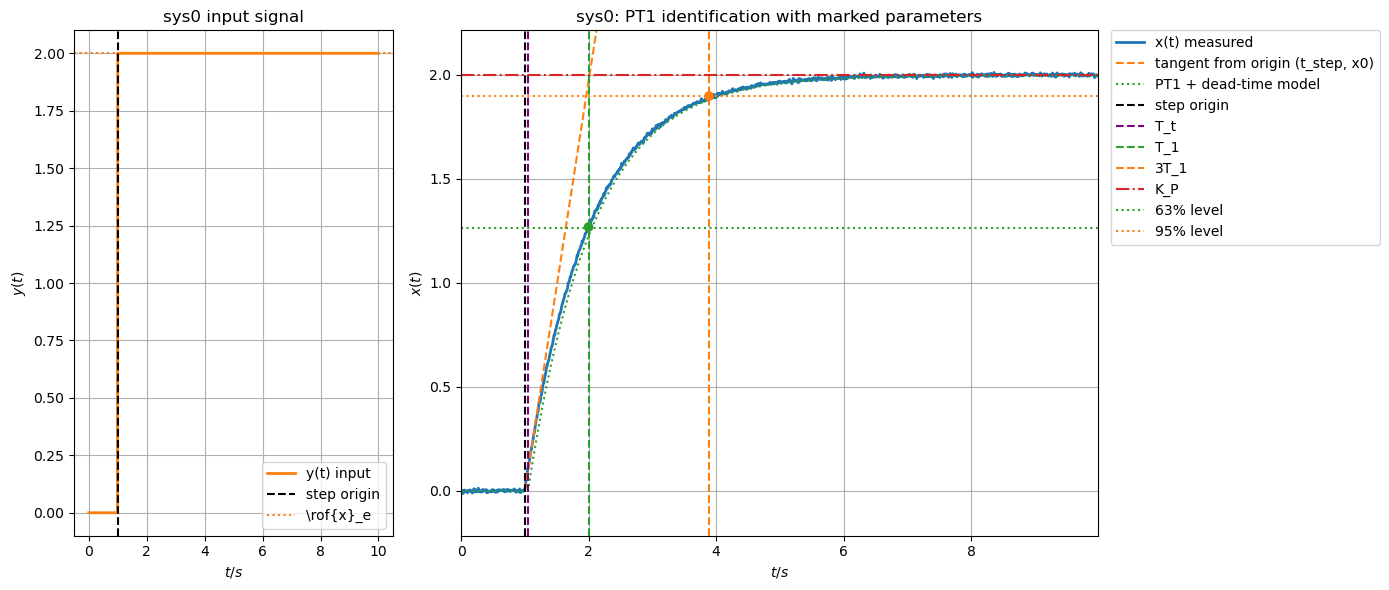

Estimated sys0 PT1 parameters:
K_P = 0.998876
T_t = 0.050000 s
T_1 = 1.000000 s
3T_1 = 2.890000 s
Übertragungsfunktion (PT1 with dead time):
G(s) = (0.998876) / (1.000000 s + 1) * exp(-0.050000 s)


In [87]:
# sys0 PT1 identification with dead time and annotated plot
t = data0[:, 0]
u = data0[:, 1]  # input y(t)
x = data0[:, 2]  # output x(t)

# Trigger time from input step (0 -> 2).
trigger_candidates = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
t_step = t[trigger_idx]

# Baseline and steady-state values.
x0 = np.mean(x[:max(1, trigger_idx)])
x_inf = np.mean(x[-10:])
u0 = np.mean(u[:max(1, trigger_idx)])
u_inf = np.mean(u[trigger_idx:])
du = u_inf - u0
dx = x_inf - x0

# Static gain Kp = Delta output / Delta input.
K_p = dx / du if abs(du) > 1e-12 else np.nan

# Work on normalized response after trigger.
t_rel = t - t_step
x_norm = (x - x0) / dx if abs(dx) > 1e-12 else np.zeros_like(x)

# Dead time T_t: first time output exceeds 5% of total rise after trigger.
post = np.arange(trigger_idx, len(t))
idx_5 = post[np.where(x_norm[post] >= 0.05)[0][0]] if np.any(x_norm[post] >= 0.05) else trigger_idx
t_t = t[idx_5] - t_step

# PT1 time markers from normalized rise.
idx_63 = post[np.where(x_norm[post] >= (1.0 - np.exp(-1.0)))[0][0]] if np.any(x_norm[post] >= (1.0 - np.exp(-1.0))) else post[-1]
idx_95 = post[np.where(x_norm[post] >= (1.0 - np.exp(-3.0)))[0][0]] if np.any(x_norm[post] >= (1.0 - np.exp(-3.0))) else post[-1]

T1 = t[idx_63] - t_step
T3 = t[idx_95] - t_step

# 63% and 95% levels in output coordinates.
x_63 = x0 + (1.0 - np.exp(-1.0)) * dx
x_95 = x0 + (1.0 - np.exp(-3.0)) * dx

# Tangent from the local origin (t_step, x0), slope from early post-step segment.
fit_end = min(trigger_idx + 8, len(t))
if fit_end > trigger_idx + 1:
    slope, _ = np.polyfit(t[trigger_idx:fit_end], x[trigger_idx:fit_end], 1)
else:
    slope = 0.0

# Draw tangent only in the identification region to keep the plot scale readable.
tangent = np.full_like(t, np.nan, dtype=float)
tangent_end_time = min(t_step + T3, t[-1])
tangent_mask = (t >= t_step) & (t <= tangent_end_time)
tangent[tangent_mask] = x0 + slope * (t[tangent_mask] - t_step)

# PT1 + dead-time model response for comparison.
x_model = np.where(t_rel >= t_t, x0 + dx * (1.0 - np.exp(-(t_rel - t_t) / max(T1, 1e-12))), x0)

# Two-panel plot: left input, right system response with markers.
fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2]})

# Left: input function.
ax_in.plot(t, u, color='tab:orange', label='y(t) input', linewidth=2)
ax_in.axvline(t_step, color='black', linestyle='--', label='step origin')
ax_in.axhline(u_inf, color='tab:orange', linestyle=':', label=r'\rof{x}_e')
ax_in.set_title('sys0 input signal')
ax_in.set_xlabel('$t/s$')
ax_in.set_ylabel('$y(t)$')
ax_in.grid()
ax_in.legend(loc='best')

# Right: output and PT1 identification markers.
ax_out.plot(t, x, label='x(t) measured', linewidth=2)
ax_out.plot(t, tangent, '--', label='tangent from origin (t_step, x0)')
ax_out.plot(t, x_model, ':', label='PT1 + dead-time model')

ax_out.axvline(t_step, color='black', linestyle='--', label='step origin')
ax_out.axvline(t_step + t_t, color='purple', linestyle='--', label='T_t')
ax_out.axvline(t_step + T1, color='tab:green', linestyle='--', label='T_1')
ax_out.axvline(t_step + T3, color='tab:orange', linestyle='--', label='3T_1')

# Requested rename: show steady-state output line as K_P in the legend.
ax_out.axhline(x_inf, color='tab:red', linestyle='-.', label='K_P')
ax_out.axhline(x_63, color='tab:green', linestyle=':', label='63% level')
ax_out.axhline(x_95, color='tab:orange', linestyle=':', label='95% level')
ax_out.scatter([t_step + T1, t_step + T3], [x[idx_63], x[idx_95]], color=['tab:green', 'tab:orange'], zorder=5)

# Keep readable axis range based on output signal.
y_min = np.min(x)
y_max = np.max(x)
y_pad = 0.1 * (y_max - y_min) if y_max > y_min else 1.0
ax_out.set_xlim(t[0], t[-1])
ax_out.set_ylim(y_min - y_pad, y_max + y_pad)

ax_out.set_title('sys0: PT1 identification with marked parameters')
ax_out.set_xlabel('$t/s$')
ax_out.set_ylabel('$x(t)$')
ax_out.grid()
ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

plt.tight_layout()
plt.show()

print('Estimated sys0 PT1 parameters:')
print(f'K_P = {K_p:.6f}')
print(f'T_t = {t_t:.6f} s')
print(f'T_1 = {T1:.6f} s')
print(f'3T_1 = {T3:.6f} s')
print('Übertragungsfunktion (PT1 with dead time):')
print(f'G(s) = ({K_p:.6f}) / ({T1:.6f} s + 1) * exp(-{t_t:.6f} s)')

In [ ]:
# for sys1 PT_2 values are 
# 	- Übertragungsfunktion
#	- D dampening 
#	- HK+/- (Hüllenkurve) 
#	- T_d period time 
#	- t_max (überschwingzeit)
#	- Kreisfrequenz
#	- h_max (Absolute überschwingweite)
#	- absolute überschwingweite
#	- normierter überschwingweite (in procent)
#	- h(inf)





In [ ]:
# for sys2 IT_1 values are 
# 	- Übertragungsfunktion
#	- T_1 schnitt von lim->inf tangente and the time axis 
#	- K_I steigung von der h(t) tangente 
#	- T_t (deadtime)




#### Calculating the system deviation from the optimal system parametric response values

#### Section to plot the Regeungstechnische and Simulink Model each system 